#Denoising

You are given a clean image below (left) and an image corrupted by additive white Gaussian noise (right). Apply the following filtering operations:

  
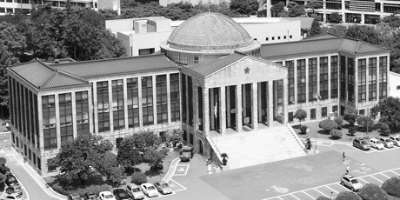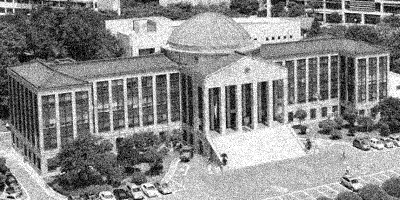

1.	Filter the noisy image using an average filter with kernel size as 1) 3x3, 2) 5x5, 3) 7x7, and 4) 9x9. Visualize 4 output images and explain the effect of increasing the kernel size on the average filtering.

In [2]:
import cv2, numpy as np
import matplotlib.pyplot as plt
from skimage.metrics import peak_signal_noise_ratio as psnr, structural_similarity as ssim

clean = cv2.imread("clean.png", cv2.IMREAD_GRAYSCALE)
noisy = cv2.imread("noisy.png", cv2.IMREAD_GRAYSCALE)
print(f"Noisy: PSNR={psnr(clean, noisy):.2f} dB, SSIM={ssim(clean, noisy):.4f}")

Noisy: PSNR=22.31 dB, SSIM=0.7145


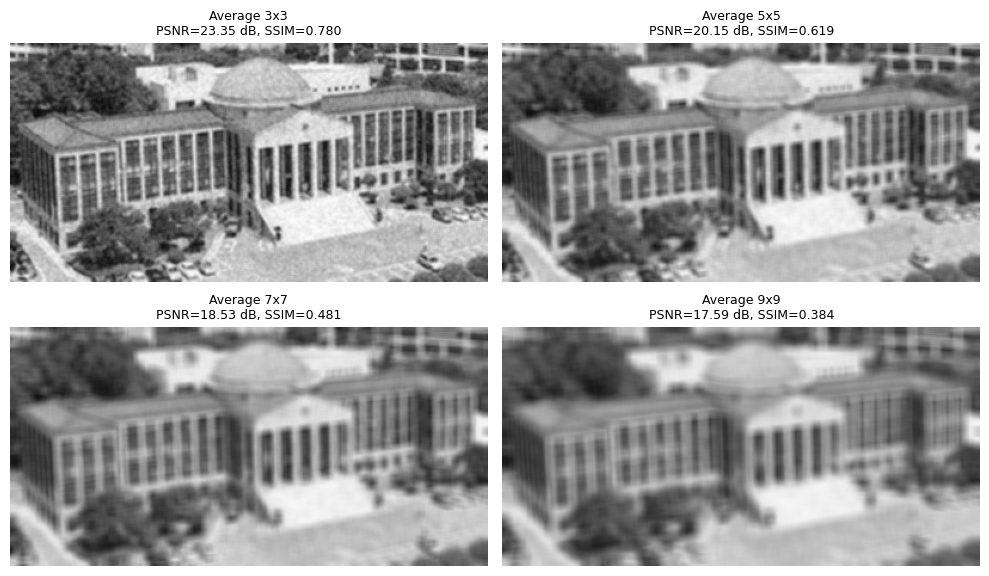

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6))

avg_results = []
for ax, k in zip(axes.ravel(), (3, 5, 7, 9)):
    out = cv2.blur(noisy, (k, k))
    avg_results.append((f"Average {k}x{k}", out))
    ax.imshow(out, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"Average {k}x{k}\nPSNR={psnr(clean, out):.2f} dB, SSIM={ssim(clean, out):.3f}", fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

##Observation
As the kernel grows each output pixel ends up averaging neighboring pixels. This reduces noise. Makes the image appear smoother.. Since every pixel, in the window is given the same weight, edges and fine details start to blur. The blurring effect increases quickly while the noise reduction slows down. Because of this the blur error grows faster than the noise error shrinks. That’s why PSNR and SSIM values go down. At a 3x3 kernel the PSNR is 23.35 dB. At a 9x9 kernel it drops to 17.59 dB.

2.	Filter the noisy image using a 9×9 Gaussian filter with sigma equal to 1) 0.5, 2) 1, 3) 2, and 4) 4. Visualize 4 output images and explain the effect of increasing the sigma value on the Gaussian filtering.

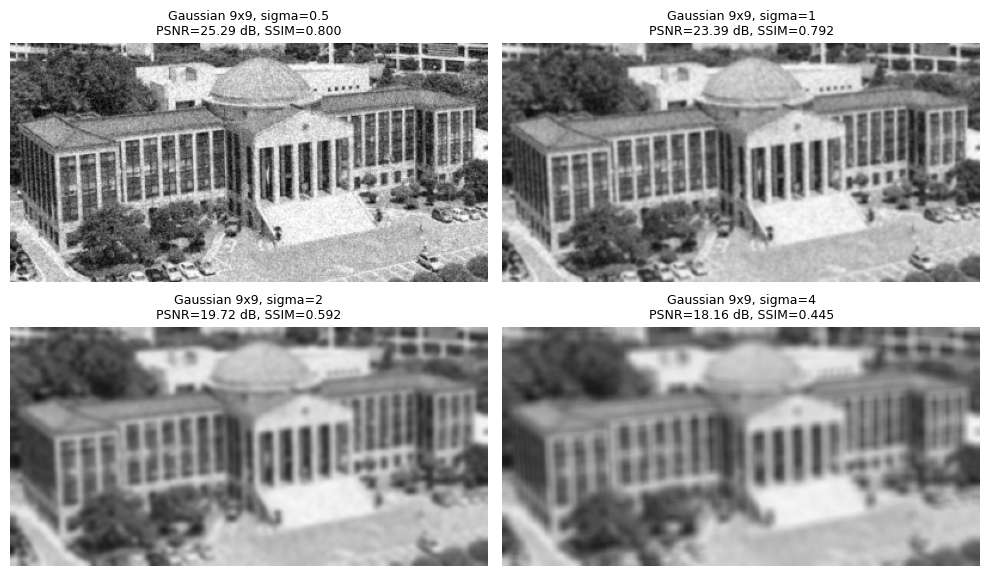

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6))

gau_results = []
for ax, s in zip(axes.ravel(), (0.5, 1, 2, 4)):
    out = cv2.GaussianBlur(noisy, (9, 9), s)
    gau_results.append((f"Gaussian 9x9, sigma={s}", out))
    ax.imshow(out, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"Gaussian 9x9, sigma={s}\nPSNR={psnr(clean, out):.2f} dB, SSIM={ssim(clean, out):.3f}", fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

##Observation
Sigma controls how far the smoothing effect reaches. When sigma is small like 0.5 the weight is mostly, on the center pixel. This means little blur happens and edges remain sharp. As sigma gets larger the weights spread out across the 9x9 window. This reduces noise but it also causes more blur. When sigma reaches 4 the kernel becomes almost flat like a simple 9x9 average filter. The quality drops as sigma grows. It starts at 25.29 dB for sigma 0.5. Goes down to 18.16 dB for sigma 4.

3.	Which filter and parameter combination shows the best denoising performance (among the above 8 filters)?

Filter                        PSNR (dB)     SSIM
Average 3x3                       23.35   0.7804
Average 5x5                       20.15   0.6188
Average 7x7                       18.53   0.4806
Average 9x9                       17.59   0.3840
Gaussian 9x9, sigma=0.5           25.29   0.8002
Gaussian 9x9, sigma=1             23.39   0.7915
Gaussian 9x9, sigma=2             19.72   0.5920
Gaussian 9x9, sigma=4             18.16   0.4451

Best filter: Gaussian 9x9, sigma=0.5


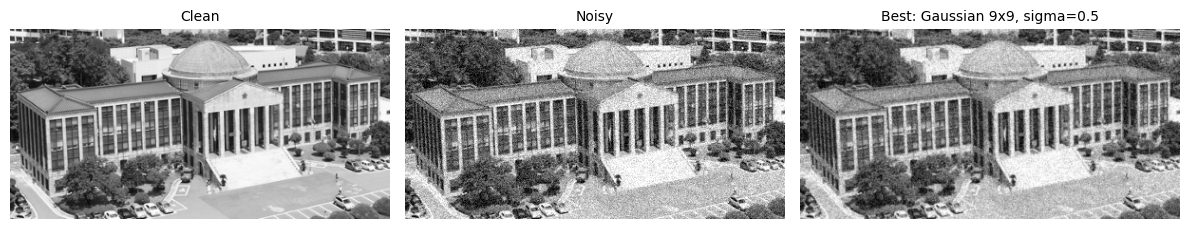

In [5]:
plt.close("all")
all_results = avg_results + gau_results

print(f"{'Filter':28s} {'PSNR (dB)':>10s} {'SSIM':>8s}")
for name, im in all_results:
    print(f"{name:28s} {psnr(clean, im):10.2f} {ssim(clean, im):8.4f}")

best_name, best_img = max(all_results, key=lambda t: psnr(clean, t[1]))
print("\nBest filter:", best_name)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, (im, t) in zip(axes, [(clean, "Clean"), (noisy, "Noisy"), (best_img, f"Best: {best_name}")]):
    ax.imshow(im, cmap="gray", vmin=0, vmax=255)
    ax.set_title(t, fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

##Observation
The best filter is the 9x9 Gaussian with sigma to 0.5 (PSNR 25.29 dB, SSIM 0.800). This filter removes an amount of noise while keeping edges sharp. The stronger filters blur much that they score worse, than the noisy image (22.31 dB).